In [1]:
import pandas as pd


In [2]:
geracao = pd.read_csv("../data/Plant_1_Generation_Data.csv")

geracao["DATE_TIME"] = pd.to_datetime(geracao["DATE_TIME"], format="%d-%m-%Y %H:%M")

print(geracao.shape)
print(geracao["DATE_TIME"].min(), geracao["DATE_TIME"].max())

(68778, 7)
2020-05-15 00:00:00 2020-06-17 23:45:00


In [3]:
clima = pd.read_csv("../data/Plant_1_Weather_Sensor_Data.csv")

clima["DATE_TIME"] = pd.to_datetime(clima["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

print(clima.shape)
print(clima["DATE_TIME"].min(), clima["DATE_TIME"].max())

(3182, 6)
2020-05-15 00:00:00 2020-06-17 23:45:00


In [4]:
clima.head()

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [5]:
geracao.head()


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [6]:
print(geracao["SOURCE_KEY"].nunique())
print(geracao.groupby("DATE_TIME").size().head())


22
DATE_TIME
2020-05-15 00:00:00    21
2020-05-15 00:15:00    21
2020-05-15 00:30:00    21
2020-05-15 00:45:00    21
2020-05-15 01:00:00    22
dtype: int64


In [7]:
print(geracao.groupby("DATE_TIME").size().value_counts())

22    3057
10      32
21      27
14      23
18      14
4        2
20       1
16       1
19       1
Name: count, dtype: int64


In [8]:
potencia = geracao.groupby("DATE_TIME")["AC_POWER"].sum().reset_index()

print(potencia.shape)
print(potencia.head())

(3158, 2)
            DATE_TIME  AC_POWER
0 2020-05-15 00:00:00       0.0
1 2020-05-15 00:15:00       0.0
2 2020-05-15 00:30:00       0.0
3 2020-05-15 00:45:00       0.0
4 2020-05-15 01:00:00       0.0


In [9]:
dados = pd.merge(potencia, clima, on="DATE_TIME")

print(dados.shape)
print(dados.head())

(3157, 7)
            DATE_TIME  AC_POWER  PLANT_ID       SOURCE_KEY  \
0 2020-05-15 00:00:00       0.0   4135001  HmiyD2TTLFNqkNe   
1 2020-05-15 00:15:00       0.0   4135001  HmiyD2TTLFNqkNe   
2 2020-05-15 00:30:00       0.0   4135001  HmiyD2TTLFNqkNe   
3 2020-05-15 00:45:00       0.0   4135001  HmiyD2TTLFNqkNe   
4 2020-05-15 01:00:00       0.0   4135001  HmiyD2TTLFNqkNe   

   AMBIENT_TEMPERATURE  MODULE_TEMPERATURE  IRRADIATION  
0            25.184316           22.857507          0.0  
1            25.084589           22.761668          0.0  
2            24.935753           22.592306          0.0  
3            24.846130           22.360852          0.0  
4            24.621525           22.165423          0.0  


In [10]:
instante = geracao[geracao["DATE_TIME"] == "2020-05-15 12:00:00"]
print(instante["AC_POWER"].sum())
print(dados[dados["DATE_TIME"] == "2020-05-15 12:00:00"]["AC_POWER"])


15250.8083332
48    15250.808333
Name: AC_POWER, dtype: float64


In [11]:
dados["HORA"] = dados["DATE_TIME"].dt.hour + dados["DATE_TIME"].dt.minute/60

In [12]:
dados = dados[["DATE_TIME", "IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "HORA", "AC_POWER"]]

print(dados.shape)
print(dados.isna().sum())

(3157, 6)
DATE_TIME              0
IRRADIATION            0
MODULE_TEMPERATURE     0
AMBIENT_TEMPERATURE    0
HORA                   0
AC_POWER               0
dtype: int64


In [13]:
print(potencia[~potencia["DATE_TIME"].isin(clima["DATE_TIME"])])

               DATE_TIME  AC_POWER
1776 2020-06-03 14:00:00    2907.7


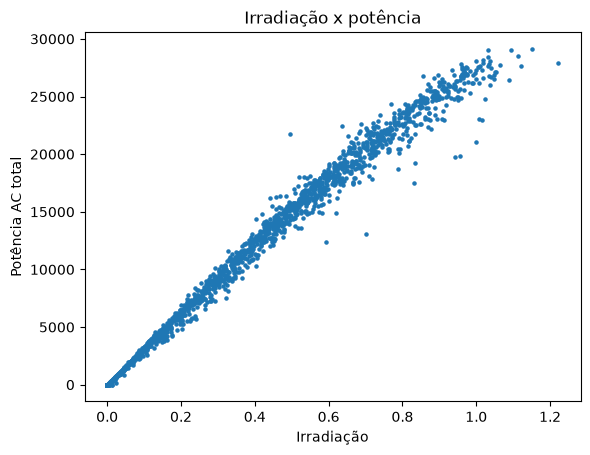

In [14]:
import matplotlib.pyplot as plt

plt.scatter(dados["IRRADIATION"], dados["AC_POWER"], s=5)
plt.xlabel("Irradiação")
plt.ylabel("Potência AC total")
plt.title("Irradiação x potência")
plt.show()

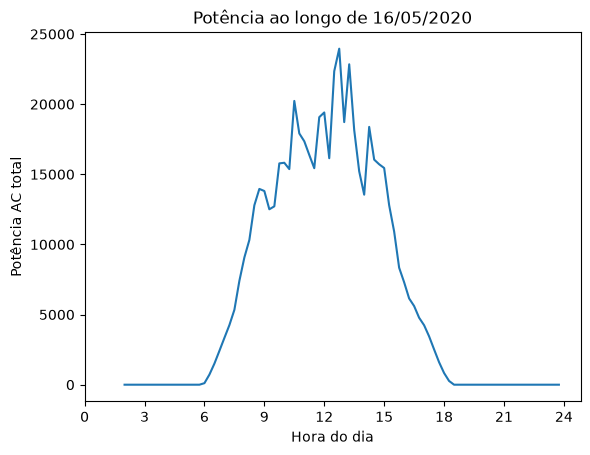

In [15]:
dia = dados[dados["DATE_TIME"].dt.date == pd.to_datetime("2020-05-16").date()]

plt.plot(dia["HORA"], dia["AC_POWER"])
plt.xticks(range(0, 25, 3))
plt.xlabel("Hora do dia")
plt.ylabel("Potência AC total")
plt.title("Potência ao longo de 16/05/2020")
plt.show()

In [16]:
import numpy as np

X = dados[["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "HORA"]].to_numpy()
Y = dados["AC_POWER"].to_numpy()

print(X.shape)
print(Y.shape)

(3157, 4)
(3157,)


In [17]:
mu = X.mean(axis=0)
sigma = X.std(axis=0)

X_norm = (X - mu) / sigma

print(mu)
print(sigma)
print(X_norm.mean(axis=0).round(6))
print(X_norm.std(axis=0))

[ 0.23010317 25.56025654 31.17545339 12.00110865]
[ 0.30130068  3.35052839 12.27074143  6.8711931 ]
[ 0.  0.  0. -0.]
[1. 1. 1. 1.]


In [18]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost = 0
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        erro = f_wb_i - y[i]
        cost = cost + erro**2
    total_cost = cost / (2*m)
    return total_cost
    

In [19]:
X_t = np.array([[1, 2], [3, 4], [5, 6]])
Y_t = np.array([5, 10, 14])
w_t = np.array([2, 1])
b_t = 1

print(compute_cost(X_t, Y_t, w_t, b_t))

w_zero = np.zeros(4)
b_zero = 0
print(compute_cost(X_norm, Y, w_zero, b_zero))

1.6666666666666667
59481934.39883764


In [20]:
def compute_gradient(X, Y, w, b):
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    
    for i in range(m):
        erro = (np.dot(X[i], w) + b) - Y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + erro * X[i, j]
        dj_db = dj_db + erro
        
    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_db, dj_dw

In [21]:
dj_db_t, dj_dw_t = compute_gradient(X_t, Y_t, w_t, b_t)
print(dj_db_t)
print(dj_dw_t)

1.3333333333333333
[6.         7.33333333]


In [22]:
def gradient_descent(X, Y, w_in, b_in, alpha, num_iters):
    w = w_in.copy()
    b = b_in
    historico_custo = []
    
    for it in  range(num_iters): 
        dj_db, dj_dw = compute_gradient(X, Y, w, b)
        
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        
        historico_custo.append(compute_cost(X, Y, w, b))
        
        if it % 100 == 0:
            print(f"Iteração {it}: custo {historico_custo[-1]:.1f}")
        
    return w, b, historico_custo

In [23]:
w_ini = np.zeros(4)
b_ini = 0
alpha = 0.1
num_iters = 1000

w_final, b_final, historico = gradient_descent(X_norm, Y, w_ini, b_ini, alpha, num_iters)

print(w_final)
print(b_final)

Iteração 0: custo 39550508.3
Iteração 100: custo 418467.6
Iteração 200: custo 370986.2
Iteração 300: custo 353510.0
Iteração 400: custo 340448.4
Iteração 500: custo 330527.1
Iteração 600: custo 322989.3
Iteração 700: custo 317262.3
Iteração 800: custo 312911.2
Iteração 900: custo 309605.3
[ 7.53054087e+03 -3.02722837e+02  1.29683909e+03  3.67095173e+00]
6704.830533835196


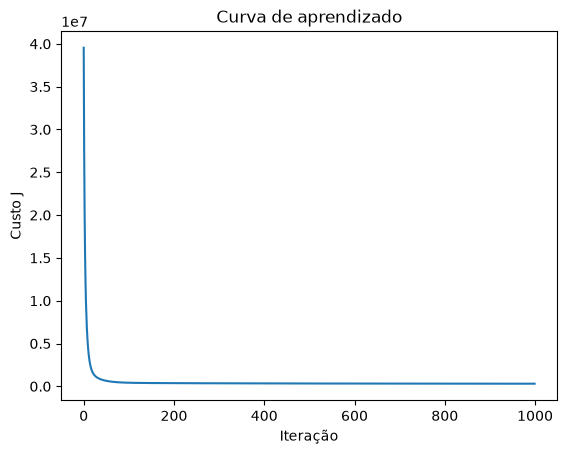

In [24]:
plt.plot(historico)
plt.xlabel("Iteração")
plt.ylabel("Custo J")
plt.title("Curva de aprendizado")
plt.show()

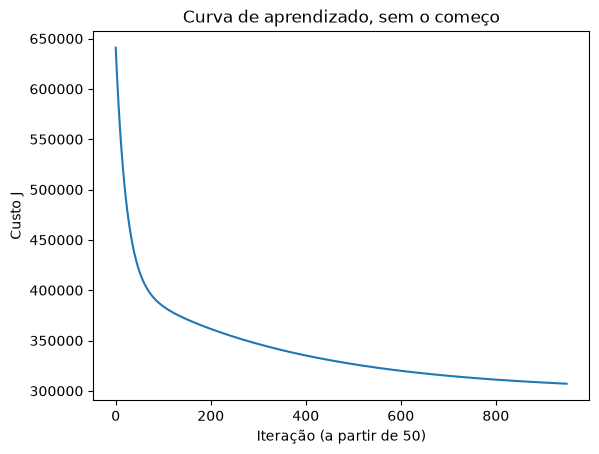

In [25]:
plt.plot(historico[50:])
plt.xlabel("Iteração (a partir de 50)")
plt.ylabel("Custo J")
plt.title("Curva de aprendizado, sem o começo")
plt.show()

In [26]:
print(historico[-2] - historico[-1])
print((historico[-2] - historico[-1]) / historico[-1])

21.91464424500009
7.135637886835219e-05


Iteração 0: custo 57251129.8
Iteração 100: custo 5216024.7
Iteração 200: custo 1779115.1
Iteração 0: custo 39550508.3
Iteração 100: custo 418467.6
Iteração 200: custo 370986.2
Iteração 0: custo 12638579.1
Iteração 100: custo 330065.6
Iteração 200: custo 306947.1


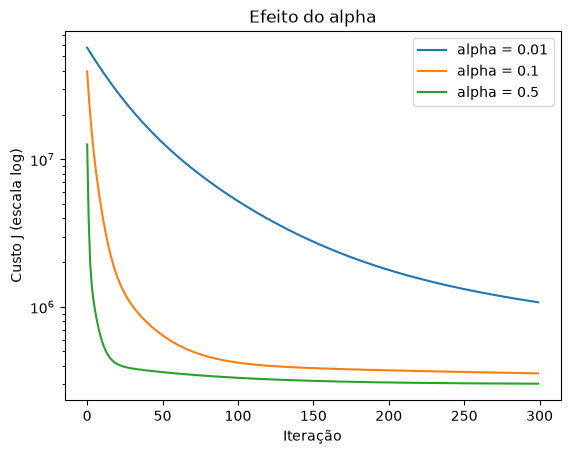

In [27]:
for alpha in [0.01, 0.1, 0.5]:
    _, _, hist = gradient_descent(X_norm, Y, np.zeros(4), 0, alpha, 300)
    plt.plot(hist, label=f"alpha = {alpha}")

plt.yscale("log")
plt.legend()
plt.xlabel("Iteração")
plt.ylabel("Custo J (escala log)")
plt.title("Efeito do alpha")
plt.show()
    

In [28]:
_, _, h_alto = gradient_descent(X_norm, Y, np.zeros(4), 0, 0.8, 10)
print(h_alto)

Iteração 0: custo 47909095.9
[np.float64(47909095.916440085), np.float64(64633371.42968166), np.float64(89728578.61560994), np.float64(125240468.79208893), np.float64(175245402.06311375), np.float64(245535036.07335255), np.float64(344256173.98565173), np.float64(482853625.4935441), np.float64(677396838.7923973), np.float64(950442949.6248724)]


In [29]:
w_fin, b_fin, hist_fin = gradient_descent(X_norm, Y, np.zeros(4), 0, 0.5, 1000)

print(w_fin)
print(b_fin)


Iteração 0: custo 12638579.1
Iteração 100: custo 330065.6
Iteração 200: custo 306947.1
Iteração 300: custo 301116.4
Iteração 400: custo 299645.9
Iteração 500: custo 299275.0
Iteração 600: custo 299181.5
Iteração 700: custo 299157.9
Iteração 800: custo 299151.9
Iteração 900: custo 299150.4
[8138.85075545  -18.932227    459.97300576  -11.81208977]
6704.830533835199


In [30]:
Y_prev = np.dot(X_norm, w_fin) + b_fin
erro = Y_prev - Y

rmse = np.sqrt(np.mean(erro ** 2))
r2 = 1 - np.sum(erro ** 2) / np.sum((Y - Y.mean()) ** 2)

print(f"RMSE: {rmse:.1f} KW")
print(f"R²: {r2:.4f}")

RMSE: 773.5 KW
R²: 0.9919


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

scaler = StandardScaler()
X_sk = scaler.fit_transform(X)

print(np.allclose(X_sk, X_norm))

modelo = LinearRegression()
modelo.fit(X_sk, Y)

print(modelo.coef_)
print(modelo.intercept_)

True
[8141.3126423   -17.78369992  456.58613063  -11.87475109]
6704.830533835199


In [37]:
Y_prev_sk = modelo.predict(X_sk)

erro_sk = Y_prev_sk - Y
rmse_sk = np.sqrt(np.mean(erro_sk ** 2))

print(f"RMSE sklearn: {rmse_sk:.1f} KW")
print(f"R² sklearn: {modelo.score(X_sk, Y):.4f}")

RMSE sklearn: 773.5 KW
R² sklearn: 0.9919


In [36]:
Y_prev_sk = modelo.predict(X_sk)

erro_sk = Y_prev_sk - Y
rmse_sk = np.sqrt(np.mean(erro_sk ** 2))

print(f"RMSE à mão:   {rmse:.4f} kW")
print(f"RMSE sklearn: {rmse_sk:.4f} kW")

RMSE à mão:   773.4986 kW
RMSE sklearn: 773.4985 kW


In [39]:
dados["DIA"] = dados["DATE_TIME"].dt.date

dias = sorted(dados["DIA"].unique())
print(len(dias))

dias_teste = dias[-7:]
mask_teste = dados["DIA"].isin(dias_teste).to_numpy()

X_treino, Y_treino = X[~mask_teste], Y[~mask_teste]
X_teste, Y_teste = X[mask_teste], Y[mask_teste]

print(X_treino.shape, X_teste.shape)

34
(2487, 4) (670, 4)


In [40]:
scaler = StandardScaler()
X_treino_n = scaler.fit_transform(X_treino)
X_teste_n = scaler.transform(X_teste)

modelo_lin = LinearRegression()
modelo_lin.fit(X_treino_n, Y_treino)

def calc_rmse(y_real, y_prev):
    return np.sqrt(np.mean((y_prev - y_real) ** 2))

print(f"RMSE treino: {calc_rmse(Y_treino, modelo_lin.predict(X_treino_n)):.1f} KW")
print(f"RMSE teste: {calc_rmse(Y_teste, modelo_lin.predict(X_teste_n)):.1f} KW")

RMSE treino: 777.3 KW
RMSE teste: 788.6 KW


In [43]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_treino_p = poly.fit_transform(X_treino)
X_teste_p = poly.transform(X_teste)
print(X_treino_p.shape)

scaler_p = StandardScaler()
X_treino_pn = scaler_p.fit_transform(X_treino_p)
X_teste_pn = scaler_p.transform(X_teste_p)

modelo_p2 = LinearRegression()
modelo_p2.fit(X_treino_pn, Y_treino)

print(f"RMSE treino: {calc_rmse(Y_treino, modelo_p2.predict(X_treino_pn)):.1f} kW")
print(f"RMSE teste:  {calc_rmse(Y_teste, modelo_p2.predict(X_teste_pn)):.1f} kW")

(2487, 14)
RMSE treino: 637.9 kW
RMSE teste:  508.7 kW


In [44]:
print(Y_treino.mean(), Y_teste.mean())
print(Y_treino.std(),  Y_teste.std())

6891.744837342566 6011.015798278746
8787.328041635308 7841.56125849427


In [45]:
for grau in [1, 2, 3, 4, 5]:
    poly = PolynomialFeatures(degree=grau, include_bias=False)
    Xtr = poly.fit_transform(X_treino)
    Xte = poly.transform(X_teste)

    sc = StandardScaler()
    Xtr = sc.fit_transform(Xtr)
    Xte = sc.transform(Xte)

    m = LinearRegression().fit(Xtr, Y_treino)

    print(f"grau {grau}: colunas {Xtr.shape[1]:3d} | "
          f"treino {calc_rmse(Y_treino, m.predict(Xtr)):8.1f} | "
          f"teste {calc_rmse(Y_teste, m.predict(Xte)):8.1f}")

grau 1: colunas   4 | treino    777.3 | teste    788.6
grau 2: colunas  14 | treino    637.9 | teste    508.7
grau 3: colunas  34 | treino    598.7 | teste    416.2
grau 4: colunas  69 | treino    574.2 | teste    462.0
grau 5: colunas 125 | treino    555.1 | teste    481.8


In [46]:
def avaliar(grau, mask_teste):
    poly = PolynomialFeatures(degree=grau, include_bias=False)
    Xtr = poly.fit_transform(X[~mask_teste])
    Xte = poly.transform(X[mask_teste])

    sc = StandardScaler()
    Xtr = sc.fit_transform(Xtr)
    Xte = sc.transform(Xte)

    m = LinearRegression().fit(Xtr, Y[~mask_teste])
    return calc_rmse(Y[mask_teste], m.predict(Xte))

janelas = {
    "últimos 7":      dias[-7:],
    "7 anteriores":   dias[-14:-7],
    "7 antes dessas": dias[-21:-14],
}

for nome, dias_j in janelas.items():
    mask = dados["DIA"].isin(dias_j).to_numpy()
    linha = f"{nome:15s}"
    for g in [1, 2, 3, 4, 5]:
        linha = linha + f" | grau {g}: {avaliar(g, mask):7.1f}"
    print(linha)

últimos 7       | grau 1:   788.6 | grau 2:   508.7 | grau 3:   416.2 | grau 4:   462.0 | grau 5:   481.8
7 anteriores    | grau 1:   947.4 | grau 2:   810.8 | grau 3:   802.6 | grau 4:   797.7 | grau 5:   792.0
7 antes dessas  | grau 1:   803.9 | grau 2:   619.8 | grau 3:   626.3 | grau 4:   671.4 | grau 5:   639.7


In [47]:
# Bobo 1: sempre a média de potência do treino
Y_prev_b1 = np.full(len(Y_teste), Y_treino.mean())

# Bobo 2: a média de potência do treino naquele horário do dia
medias_hora = dados[~mask_teste].groupby("HORA")["AC_POWER"].mean()
Y_prev_b2 = dados.loc[mask_teste, "HORA"].map(medias_hora).to_numpy()

print(f"Bobo 1 (média geral):    {calc_rmse(Y_teste, Y_prev_b1):.1f} kW")
print(f"Bobo 2 (média por hora): {calc_rmse(Y_teste, Y_prev_b2):.1f} kW")

Bobo 1 (média geral):    7890.9 kW
Bobo 2 (média por hora): 2936.4 kW


In [48]:
from sklearn.linear_model import Ridge

def avaliar_ridge(grau, lam, mask_teste):
    poly = PolynomialFeatures(degree=grau, include_bias=False)
    Xtr = poly.fit_transform(X[~mask_teste])
    Xte = poly.transform(X[mask_teste])

    sc = StandardScaler()
    Xtr = sc.fit_transform(Xtr)
    Xte = sc.transform(Xte)

    m = Ridge(alpha=lam).fit(Xtr, Y[~mask_teste])
    return calc_rmse(Y[mask_teste], m.predict(Xte))

for lam in [0.1, 1, 10, 100, 1000]:
    erros = []
    for dias_j in janelas.values():
        mask = dados["DIA"].isin(dias_j).to_numpy()
        erros.append(avaliar_ridge(5, lam, mask))
    print(f"lambda {lam:7.1f} | {erros[0]:7.1f} | {erros[1]:7.1f} | {erros[2]:7.1f} | média {np.mean(erros):7.1f}")

lambda     0.1 |   416.0 |   800.9 |   611.9 | média   609.6
lambda     1.0 |   419.9 |   802.0 |   599.8 | média   607.2
lambda    10.0 |   488.0 |   818.2 |   614.1 | média   640.1
lambda   100.0 |   706.3 |   883.8 |   709.0 | média   766.4
lambda  1000.0 |  1502.9 |  1275.0 |  1184.6 | média  1320.9


In [49]:
grau = 3

for lam in [0.01, 0.1, 1, 10, 100]:
    erros = []
    for dias_j in janelas.values():
        mask = dados["DIA"].isin(dias_j).to_numpy()
        erros.append(avaliar_ridge(grau, lam, mask))
    print(f"grau {grau} | lambda {lam:7.2f} | {erros[0]:7.1f} | {erros[1]:7.1f} | {erros[2]:7.1f} | média {np.mean(erros):7.1f}")

grau 3 | lambda    0.01 |   408.8 |   792.1 |   595.1 | média   598.7
grau 3 | lambda    0.10 |   418.9 |   788.9 |   586.7 | média   598.2
grau 3 | lambda    1.00 |   456.5 |   793.6 |   598.0 | média   616.0
grau 3 | lambda   10.00 |   519.8 |   805.5 |   617.1 | média   647.5
grau 3 | lambda  100.00 |   858.4 |   920.2 |   751.1 | média   843.2


In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

dd = dados[dados["IRRADIATION"] > 0]
mask_t = dd["DIA"].isin(dias_teste).to_numpy()

limiar = dd.loc[~mask_t, "AC_POWER"].median()
y_cls = (dd["AC_POWER"] >= limiar).astype(int).to_numpy()

colunas = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "HORA"]
X_cls = dd[colunas].to_numpy()

print(f"Limiar: {limiar:.0f} kW")
print("Linhas de treino / teste:", (~mask_t).sum(), mask_t.sum())
print(f"Proporção de 'boa' no treino: {y_cls[~mask_t].mean():.2f}")
print(f"Proporção de 'boa' no teste:  {y_cls[mask_t].mean():.2f}")

Limiar: 12695 kW
Linhas de treino / teste: 1386 368
Proporção de 'boa' no treino: 0.50
Proporção de 'boa' no teste:  0.45


In [51]:
sc_c = StandardScaler()
Xc_tr = sc_c.fit_transform(X_cls[~mask_t])
Xc_te = sc_c.transform(X_cls[mask_t])
y_tr, y_te = y_cls[~mask_t], y_cls[mask_t]

clf = LogisticRegression()
clf.fit(Xc_tr, y_tr)

print(f"Acurácia treino: {clf.score(Xc_tr, y_tr):.3f}")
print(f"Acurácia teste:  {clf.score(Xc_te, y_te):.3f}")
print(f"Chute da classe mais comum (teste): {max(y_te.mean(), 1 - y_te.mean()):.3f}")

print("Pesos:", clf.coef_[0])
print("b:", clf.intercept_[0])
print(confusion_matrix(y_te, clf.predict(Xc_te)))

z = np.dot(Xc_te, clf.coef_[0]) + clf.intercept_[0]
p_mao = 1 / (1 + np.exp(-z))
print(np.allclose(p_mao, clf.predict_proba(Xc_te)[:, 1]))

Acurácia treino: 0.977
Acurácia teste:  0.965
Chute da classe mais comum (teste): 0.552
Pesos: [ 7.42749554 -0.71526729  1.71919827  0.3972479 ]
b: 0.20284698265563608
[[199   4]
 [  9 156]]
True


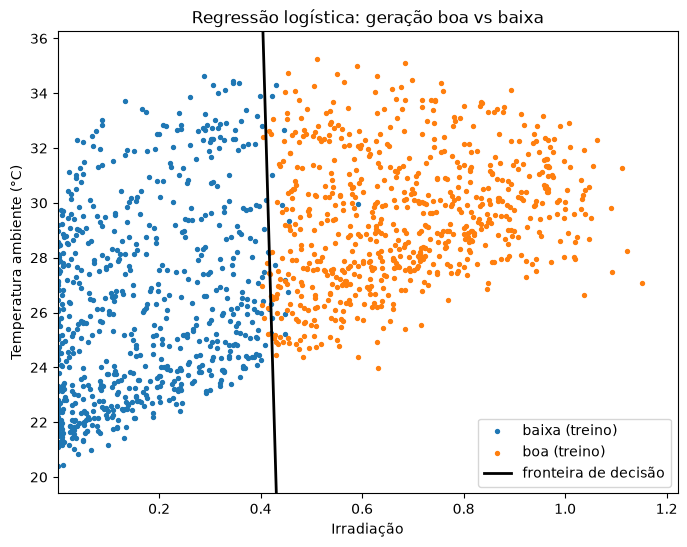

In [52]:
cols2 = ["IRRADIATION", "AMBIENT_TEMPERATURE"]
X2 = dd[cols2].to_numpy()

sc2 = StandardScaler()
X2_tr = sc2.fit_transform(X2[~mask_t])
clf2 = LogisticRegression().fit(X2_tr, y_tr)

w1, w2 = clf2.coef_[0]
b2 = clf2.intercept_[0]
mu1, mu2 = sc2.mean_
s1, s2 = sc2.scale_

x1 = np.linspace(X2[:, 0].min(), X2[:, 0].max(), 100)
x2 = mu2 - (s2 / w2) * (b2 + w1 * (x1 - mu1) / s1)

plt.figure(figsize=(8, 6))
plt.scatter(X2[~mask_t][y_tr == 0, 0], X2[~mask_t][y_tr == 0, 1], s=8, c="tab:blue", label="baixa (treino)")
plt.scatter(X2[~mask_t][y_tr == 1, 0], X2[~mask_t][y_tr == 1, 1], s=8, c="tab:orange", label="boa (treino)")
plt.plot(x1, x2, "k-", linewidth=2, label="fronteira de decisão")
plt.xlim(X2[:, 0].min(), X2[:, 0].max())
plt.ylim(X2[:, 1].min() - 1, X2[:, 1].max() + 1)
plt.xlabel("Irradiação")
plt.ylabel("Temperatura ambiente (°C)")
plt.title("Regressão logística: geração boa vs baixa")
plt.legend()
plt.show()

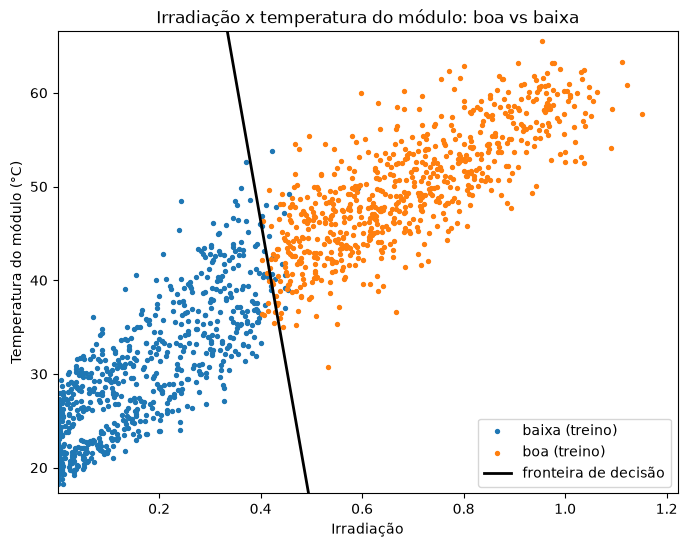

Pesos (irradiação, módulo): 7.632863371797029 0.9696816185943935
b: 0.18561439085194995
Acurácia treino: 0.981
Acurácia teste:  0.967
Correlação irradiação x módulo: 0.932596434136217


In [53]:
cols3 = ["IRRADIATION", "MODULE_TEMPERATURE"]
X3 = dd[cols3].to_numpy()

sc3 = StandardScaler()
X3_tr = sc3.fit_transform(X3[~mask_t])
clf3 = LogisticRegression().fit(X3_tr, y_tr)

w1m, w2m = clf3.coef_[0]
b3 = clf3.intercept_[0]
mu1m, mu2m = sc3.mean_
s1m, s2m = sc3.scale_

x1m = np.linspace(X3[:, 0].min(), X3[:, 0].max(), 100)
x2m = mu2m - (s2m / w2m) * (b3 + w1m * (x1m - mu1m) / s1m)

plt.figure(figsize=(8, 6))
plt.scatter(X3[~mask_t][y_tr == 0, 0], X3[~mask_t][y_tr == 0, 1], s=8, c="tab:blue", label="baixa (treino)")
plt.scatter(X3[~mask_t][y_tr == 1, 0], X3[~mask_t][y_tr == 1, 1], s=8, c="tab:orange", label="boa (treino)")
plt.plot(x1m, x2m, "k-", linewidth=2, label="fronteira de decisão")
plt.xlim(X3[:, 0].min(), X3[:, 0].max())
plt.ylim(X3[:, 1].min() - 1, X3[:, 1].max() + 1)
plt.xlabel("Irradiação")
plt.ylabel("Temperatura do módulo (°C)")
plt.title("Irradiação x temperatura do módulo: boa vs baixa")
plt.legend()
plt.show()

print("Pesos (irradiação, módulo):", w1m, w2m)
print("b:", b3)
print(f"Acurácia treino: {clf3.score(X3_tr, y_tr):.3f}")
print(f"Acurácia teste:  {clf3.score(sc3.transform(X3[mask_t]), y_te):.3f}")
print("Correlação irradiação x módulo:", np.corrcoef(X3[:, 0], X3[:, 1])[0, 1])